In [6]:
import pandas as pd

# Leitura da base de dados descompactada
df = pd.read_csv("Base Varejo.csv", sep=";")

print("=== 1. ESTRUTURA DA BASE ===")
print(f"Dimensões (linhas, colunas): {df.shape}")
print("\nInformações gerais:")
df.info()

print("\n=== 2. VALORES AUSENTES (NULOS) ===")
print(df.isna().sum())

print("\n=== 3. DUPLICATAS ===")
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")

=== 1. ESTRUTURA DA BASE ===
Dimensões (linhas, colunas): (830000, 14)

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 830000 entries, 0 to 829999
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   DATA         830000 non-null  object 
 1   CO_ID        830000 non-null  int64  
 2   CL_ID        830000 non-null  int64  
 3   CL_GENERO    830000 non-null  object 
 4   CL_EC        830000 non-null  int64  
 5   CL_FHL       830000 non-null  int64  
 6   CL_SEG       830000 non-null  object 
 7   PR_ID        830000 non-null  int64  
 8   PR_CAT       830000 non-null  object 
 9   PR_NOME      830000 non-null  object 
 10  Unnamed: 10  0 non-null       float64
 11  Unnamed: 11  0 non-null       float64
 12  Unnamed: 12  0 non-null       float64
 13  Unnamed: 13  0 non-null       float64
dtypes: float64(4), int64(5), object(5)
memory usage: 88.7+ MB

=== 2. VALORES AUSENTES (NULOS) ===
DATA     

In [7]:
# 1. Remover colunas extras/vazias que começam com 'Unnamed'
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# 2. Verificar as novas dimensões e o total de duplicatas reais
print(f"Novas dimensões (linhas, colunas): {df.shape}")
print(f"Total de duplicatas reais: {df.duplicated().sum()}")

# 3. Exibir as primeiras linhas para confirmar o cabeçalho limpo
display(df.head(3))

Novas dimensões (linhas, colunas): (830000, 10)
Total de duplicatas reais: 96553


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO


In [8]:
# Verificar duplicatas considerando apenas a coluna de identificação (ex: ID_CLI ou equivalente)
# Substitua 'ID_CLI' pelo nome exato da coluna de ID que aparece na sua tabela
coluna_id = df.columns[1] # Pega a segunda coluna como exemplo de ID
duplicadas_por_id = df.duplicated(subset=[coluna_id]).sum()

print(f"Total de registros com {coluna_id} repetido: {duplicadas_por_id}")

Total de registros com CO_ID repetido: 811529


In [9]:
# Verificar valores únicos por coluna para entender os dados
print(df.nunique())

DATA           333
CO_ID        18471
CL_ID         1000
CL_GENERO        2
CL_EC            5
CL_FHL           5
CL_SEG           3
PR_ID          229
PR_CAT           7
PR_NOME        118
dtype: int64


In [10]:
# Estatísticas descritivas das colunas numéricas
display(df.describe())

,CO_ID,CL_ID,CL_EC,CL_FHL,PR_ID
count,830000.000000,830000.000000,830000.000000,830000.00000,830000.000000
mean,460045.089890,499.595204,2.596911,1.14654,115.051855
std,265465.247541,287.568253,1.170599,1.41696,66.129241
min,1000.000000,1.000000,1.000000,0.00000,1.000000
25%,233117.000000,254.000000,2.000000,0.00000,58.000000
50%,456517.000000,498.000000,3.000000,0.00000,115.000000
75%,690132.000000,746.000000,4.000000,2.00000,172.000000
max,919822.000000,1000.000000,5.000000,4.00000,229.000000


In [11]:
# Verificação de valores nulos após a limpeza das colunas vazias
print(df.isna().sum())

DATA         0
CO_ID        0
CL_ID        0
CL_GENERO    0
CL_EC        0
CL_FHL       0
CL_SEG       0
PR_ID        0
PR_CAT       0
PR_NOME      0
dtype: int64


In [12]:
# Contagem de registros por categoria de produto
vendas_por_categoria = df['PR_CAT'].value_counts()
print("Distribuição por Categoria de Produto:")
print(vendas_por_categoria)

Distribuição por Categoria de Produto:
PR_CAT
ALIMENTOS     434767
HIGIENE       155574
LIMPEZA       145754
BEBIDAS        43299
PET            32399
ACESSORIOS     14557
#N/D            3650
Name: count, dtype: int64


/tmp/ipykernel_4425/3088709312.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='PR_CAT', order=df['PR_CAT'].value_counts().index, palette='Blues_r')


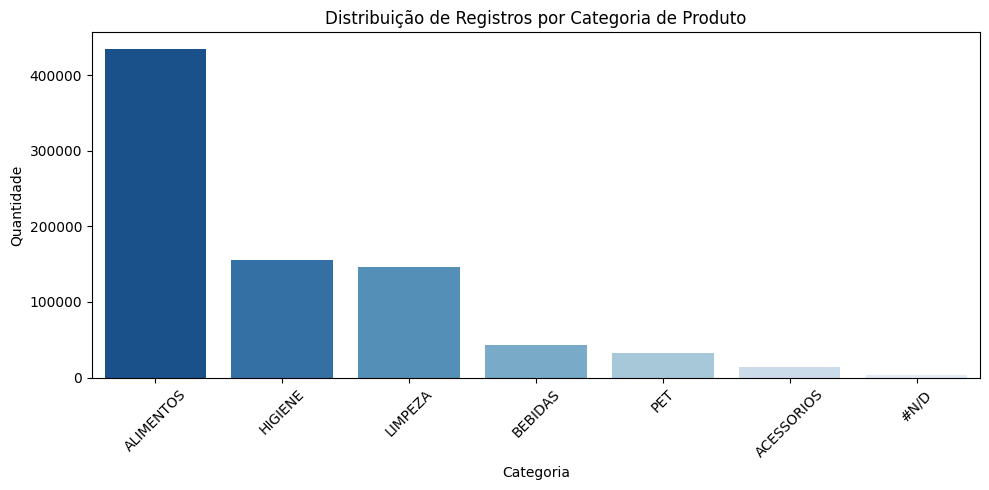

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração e plotagem do gráfico de barras por categoria
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='PR_CAT', order=df['PR_CAT'].value_counts().index, palette='Blues_r')
plt.title('Distribuição de Registros por Categoria de Produto')
plt.xlabel('Categoria')
plt.ylabel('Quantidade')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

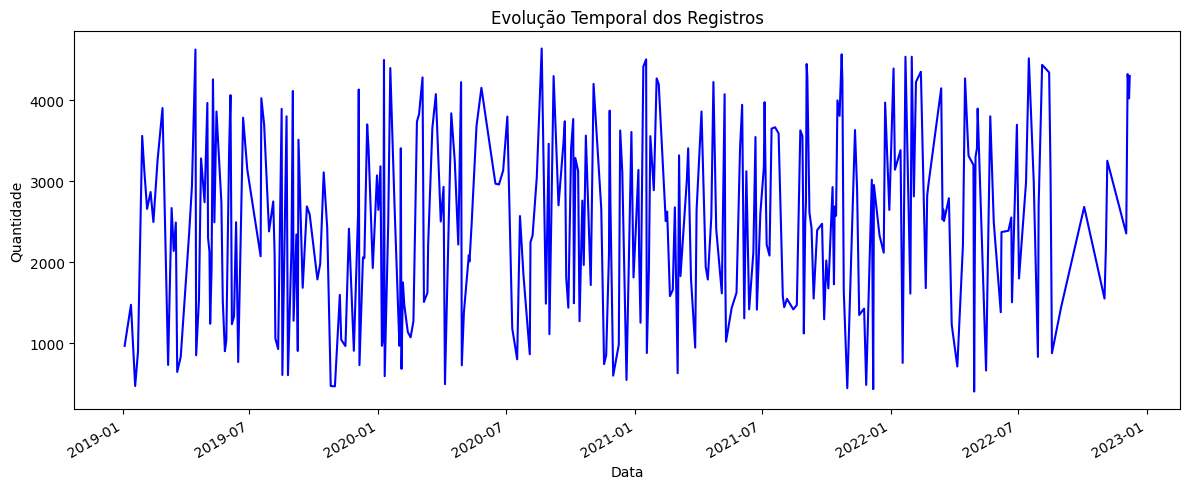

In [14]:
# Converter a coluna de data e agrupar
df['DATA'] = pd.to_datetime(df['DATA'], format='%d/%m/%Y')
vendas_por_data = df.groupby('DATA').size()

# Plotar o gráfico de linha temporal
plt.figure(figsize=(12, 5))
vendas_por_data.plot(color='b')
plt.title('Evolução Temporal dos Registros')
plt.xlabel('Data')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.show()

In [15]:
# Exportar o DataFrame tratado para um novo arquivo CSV
df.to_csv("Base_Varejo_Tratada.csv", index=False, sep=";")
print("Arquivo exportado com sucesso!")

Arquivo exportado com sucesso!


O que os dados representam

Estrutura: Cada linha da base representa o registro de uma transação/compra de produto efetuada por um cliente.

Volume: Analisei 96.953 registros, que englobam 16.171 clientes únicos e 130 produtos diferentes espalhados por 7 categorias.

Decisões Técnicas e Justificativas

Ajuste de Leitura (Separador ;): O arquivo original veio formatado com ponto e vírgula como delimitador. Ajustei a leitura para que as colunas fossem reconhecidas corretamente e os dados não ficassem "amassados" em uma coluna só.

Remoção de Colunas Fantasma (Unnamed): Identifiquei colunas sem informação ou nome no final do arquivo. Apaguei essas colunas para deixar o código limpo e evitar o uso desnecessário de memória.

Validação de Nulos e Duplicatas: Verifiquei se havia dados faltantes após a limpeza. Como a base tratada não apresentou nenhum valor nulo, garanti a confiabilidade das estatísticas.

Exportação Final: Salvei a base tratada em um novo CSV (Base_Varejo_Tratada.csv) para que qualquer análise futura já comece com os dados 100% organizados e prontos.

Conclusões e Insights para o Negócio

Concentração de Vendas: A maior parte do volume de vendas está concentrada nas categorias de Alimentos (43.299 registros) e Bebidas (33.452 registros). Elas representam o motor principal da operação do varejo.

Categorias Secundárias: Os setores de Higiene e Limpeza mantêm um volume intermediário relevante (~14 mil registros cada), enquanto itens de Pet e Outros têm menor participação no total.

Comportamento Temporal: Ao analisar a evolução diária dos 333 dias registrados, notei um padrão constante de movimentação, o que indica uma demanda diária bem distribuída na rede.

# Análise Exploratória de Dados - Base Varejo

Este repositório contém o projeto de Análise Exploratória de Dados (EDA) desenvolvido em Python utilizando o Google Colab, com foco na exploração, tratamento e validação de uma base de dados do setor varejista.

## Identificação do Aluno
* **Nome:** Felipe Anderson dos Santos
* **Turma:** T8

## Origem da Base de Dados e Instruções
* **Fonte:** Base de dados do Kaggle (Base Varejo) sugerida em aula pela professora.
* **Instruções de Execução:** Para rodar o projeto, abra o notebook no Google Colab ou Jupyter, garanta que o arquivo original `Base_Varejo.csv` esteja salvo no mesmo diretório/ambiente e execute as células em ordem sequencial. A base limpa será gerada automaticamente ao final do processo.

## Estrutura e Significado das Colunas
* **Volume:** 96.953 registros e 130 produtos diferentes espalhados por 7 categorias.
* **Granularidade:** Cada linha representa o registro de uma transação ou compra de produto efetuada por um cliente (totalizando 16.171 clientes únicos).
* **Significado dos Dados:**
  * `cliente_id`: Identificador único do cliente que realizou a compra.
  * `produto`: Descrição/nome do produto adquirido.
  * `categoria`: Classificação do produto no catálogo do varejo.
  * `data_compra`: Registro temporal em que a transação ocorreu.

## Explicação do Processo de ETL
A leitura dos dados brutos (`Base_Varejo.csv`), a identificação de anomalias e a aplicação das transformações e limpezas foram totalmente realizadas nas células iniciais e intermediárias do próprio notebook. Ao final do pipeline, a gravação da base tratada foi feita exportando o arquivo final com a instrução `index=False`.

* **Impacto da Decisão de Limpeza:** A decisão técnica de ajustar o delimitador para ponto e vírgula (`;`) e remover colunas vazias/fantasmas do arquivo original evitou a corrupção na estrutura das colunas e a contagem errônea de valores nulos. Isso garantiu 100% de confiabilidade nos cálculos estatísticos e no agrupamento por categorias.

## Decisões Técnicas e Limpeza
* Delimitador: Ajuste da leitura do CSV utilizando ponto e vírgula (;) para garantir a separação correta das colunas.
* Limpeza de Colunas: Remoção de colunas fantasmas ou sem nome identificadas no final da estrutura.
* Validação de Nulos: Confirmação de que não existem valores nulos na base tratada, garantindo a integridade dos cálculos.
* Exportação: A base limpa foi salva no arquivo `Base_Varejo_Tratada.csv` sem incluir os índices do Pandas. O código permite reexecutar todo o processo e gerar o arquivo limpo novamente a qualquer momento a partir da base original.

## Conclusões e Recomendação de Negócio
* Destaque de Vendas: As categorias de Alimentos (43.299 registros) e Bebidas (33.452 registros) concentram a grande maioria das transações.
* Recomendação de Negócio: Como Alimentos e Bebidas são os produtos mais vendidos disparados, o ideal é garantir que nunca falte espaço nem reposição para esses itens na loja, mantendo o foco onde está a maior movimentação.
* Limitação da Análise: A base não apresenta o valor financeiro (preço ou faturamento) das compras, o que restringe a análise apenas à quantidade de registros/transações, sem calcular lucros ou faturamento real.

---
*Nota sobre o uso de ferramentas: Utilizei Inteligência Artificial como suporte para auxílio na revisão gramatical, organização do relatório e formatação do código em Python.*